# Member-state statements: extraction pipeline

**Milestone 1:** one clean table of member-state statements from GA sessions 80 and 81 (plenary + Main Committees), with statistics and windows.
Retrieval (statement ↔ resolution / subject) comes afterwards and is out of scope here.

Steps:

1. Load the raw data (transcripts.un.org archive + ODS PVs)
2. Coverage table: which meetings do we have, and from which source?
3. Parse both sources into one statement schema
4. Statistics
5. Sentence splitting + windows

Kernel: the repo's uv environment (`.venv`). Add packages with `uv add <pkg>`; the notebook expects VS Code's default working directory (this folder) for the paths below.

In [3]:
from pathlib import Path

import pandas as pd

In [4]:
DATA = Path.cwd().parents[1] / "data"
TRANSCRIPTS = DATA / "transcripts"  # {slug}.json.gz + index.jsonl, written by archive_transcripts.py
ODS = DATA / "session80"  # meeting_records.jsonl (text per page) + pdf/
SESSIONS = {80, 81}

In [5]:
DATA

PosixPath('/home/janic/Workspace/Personal/repos/policy-pulse/data')

## 0a. transcripts.un.org API

A quick overview how we can fetch meeting record transcripts from the website

In [6]:
from transcripts_api_classes import *

In [7]:
BASE = "https://transcripts.un.org"
OUT = DATA / "examples"
if not OUT.exists():
    OUT.mkdir()

In [8]:
GA_BODIES = {"General Assembly"} | {
    f"{n} Committee" for n in ("First", "Second", "Third", "Fourth", "Fifth", "Sixth")
}

In [9]:
import requests
http = requests.Session()
DATE = "2026-06-30" # Choose a date to get the meeting records from 

In [10]:
resp = http.get(f"{BASE}/en/meetings.json", params={"date": DATE}, timeout=120)
resp.raise_for_status()
body = resp.json()
meetings = body["meetings"]

In [11]:
meetings

[{'title': 'UN Geneva Press Briefing: HRC, UNDP, UNHCR, UNCTAD, UNECE',
  'date': '2026-06-30T00:00:00.000Z',
  'body': None,
  'category': 'Press Conferences',
  'slug': 'briefing/geneva/2026-06-30',
  'duration': '00:54:29',
  'hasTranscript': True,
  'pageUrl': '/en/briefing/geneva/2026-06-30',
  'jsonUrl': '/en/briefing/geneva/2026-06-30.json',
  'textUrl': '/en/briefing/geneva/2026-06-30.txt'},
 {'title': '(Part 1) UNRWA Pledging Conference 2026',
  'date': '2026-06-30T00:00:00.000Z',
  'body': None,
  'category': 'Conferences',
  'slug': 'asset/k17/k17lxc4l2b',
  'duration': '02:55:07',
  'hasTranscript': True,
  'pageUrl': '/en/asset/k17/k17lxc4l2b',
  'jsonUrl': '/en/asset/k17/k17lxc4l2b.json',
  'textUrl': '/en/asset/k17/k17lxc4l2b.txt'},
 {'title': 'Palestine, Venezuela, South Sudan & other topics - Daily Press Briefing',
  'date': '2026-06-30T00:00:00.000Z',
  'body': None,
  'category': 'Press Conferences',
  'slug': 'briefing/sg/2026-06-30',
  'duration': '00:23:03',
  'ha

In [12]:
# only take ga meeting records
ga_meetings = [m for m in meetings if "ga" in m["slug"]]
ga_meetings

[{'title': 'Fifth Committee, 33rd plenary meeting - General Assembly, Second part of the resumed 80th session',
  'date': '2026-06-30T00:00:00.000Z',
  'body': 'Fifth Committee',
  'category': 'General Assembly',
  'slug': 'ga/c5/80/33',
  'duration': '01:55:52',
  'hasTranscript': True,
  'pageUrl': '/en/ga/c5/80/33',
  'jsonUrl': '/en/ga/c5/80/33.json',
  'textUrl': '/en/ga/c5/80/33.txt'},
 {'title': 'General Assembly: 94th plenary meeting, 80th session',
  'date': '2026-06-30T00:00:00.000Z',
  'body': 'General Assembly',
  'category': 'General Assembly',
  'slug': 'ga/80/94',
  'duration': '00:54:22',
  'hasTranscript': True,
  'pageUrl': '/en/ga/80/94',
  'jsonUrl': '/en/ga/80/94.json',
  'textUrl': '/en/ga/80/94.txt'}]

In [13]:
import json
# Fetch a ga meetign record transcripts
ga_mr = ga_meetings[0]
resp = http.get(f"{BASE}{ga_mr['jsonUrl']}", timeout=120)
resp.raise_for_status()

ga_mr_content = MeetingResponse.model_validate_json(resp.content)

In [14]:
# Some information about the content
print(f"Disclaimer:\n{ga_mr_content.disclaimer}")

Disclaimer:
Transcripts available through this tool are created by using automatic speech recognition and are not official records nor official documents of the United Nations. Official records and official documents are available on the Official Document System of the United Nations.


In [15]:
# Look at a transcript information
ga_mr_transcripts  = ga_mr_content.transcript
assert ga_mr_transcripts is not None
print(f"Keys in transcripts:\n{ga_mr_transcripts.model_fields_set}")
print(f"Transcript_id:\n{ga_mr_transcripts.transcript_id}")
print(f"Language:\n{ga_mr_transcripts.language}")
print(f"Topics:\n{ga_mr_transcripts.topics}") 

Keys in transcripts:
{'language', 'data', 'transcript_id', 'topics'}
Transcript_id:
azure-llm-speech-36e82d49-bf3c-4a51-be47-d852d88ee13f
Language:
en
Topics:
[Topic(key='tcc-pcc-reimbursement', label='Reimbursement for Troop and Police Contributors', description='Several statements addressed reimbursement rates for troop- and police-contributing countries and the standards for contingent-owned equipment. This was framed as recognition of the costs, responsibilities, and sacrifices borne by countries that provide personnel and equipment to UN peacekeeping.'), Topic(key='assessed-contributions', label='Assessed Contributions and Arrears', description="Many speakers stressed that the underlying cause of the UN's financial strain is late or unpaid assessed contributions. They emphasized the Charter obligation to pay in full, on time, and without conditions, while some also raised the impact of sanctions and banking constraints on payments."), Topic(key='peacekeeping-financing', label='Pea

In [16]:
# Look at the actual data in transcripts
from rich.pretty import pprint
assert ga_mr_transcripts is not None
ga_mr_data : list[Statement] =  ga_mr_transcripts.data
print(f"Num records in data: {len(ga_mr_data)}")
print("First Statement of data:")
pprint(ga_mr_data[0], max_length=2, max_string=80)

Num records in data: 51
First Statement of data:


Statement(
│   statement_number=1,
│   start=0.11,
│   paragraphs=[
│   │   Paragraph(
│   │   │   sentences=[
│   │   │   │   Sentence(
│   │   │   │   │   text='I call to order the 33rd meeting of the Fifth Committee at the second part of ou'+23,
│   │   │   │   │   start=0.11,
│   │   │   │   │   end=6.83,
│   │   │   │   │   topics=[]
│   │   │   │   ),
│   │   │   │   Sentence(
│   │   │   │   │   text='Distinguished delegates, we turn our attention to action on draft resolutions on'+94,
│   │   │   │   │   start=10.75,
│   │   │   │   │   end=21.07,
│   │   │   │   │   topics=[]
│   │   │   │   ),
│   │   │   │   ... +18
│   │   │   ]
│   │   )
│   ],
│   speaker=Speaker(affiliation='5th Committee', affiliation_full='5th Committee', group=None, function='Chair')
)

In [17]:
# Let's look at a paragraph
stmnt : Statement = ga_mr_data[0]
print(f"Number of paragraphs in first statement: {len(stmnt.paragraphs)}")
print(f"First paragraph Keys:\n{stmnt.model_fields_set}")
print(f"Number of sentences in first paragraph:\n{len(stmnt.paragraphs[0].sentences)}")
print("First sentence")
pprint(stmnt.paragraphs[0].sentences[0])

Number of paragraphs in first statement: 1
First paragraph Keys:
{'speaker', 'paragraphs', 'start', 'statement_number'}
Number of sentences in first paragraph:
20
First sentence


Sentence(
│   text='I call to order the 33rd meeting of the Fifth Committee at the second part of our resumed 80th session.',
│   start=0.11,
│   end=6.83,
│   topics=[]
)

In [18]:
# TODO: write the concrete fetcher and archiver here too!
# Probably its best to write the code in transcripts_api.py (rename it!) and then import it here!

## 0b. Fetching data from ODS

This section shows some examples on how we fetch official meeting records from ODS


In [19]:
# Config
MARC_BIBS = "https://metadata.un.org/editor/api/marc/bibs/records"
ODS_ACCESS = "https://documents.un.org/api/symbol/access"
ODS = DATA / "ods"
ODS.mkdir(parents=True, exist_ok=True)
PDF_DIR = ODS / "pdf"
PDF_DIR.mkdir(parents=True, exist_ok=True)

In [20]:
from pydantic import BaseModel, Field, ValidationError


class MARCEntry(BaseModel):
    _id: int
    # agendas: seems empty?
    # basket: empty too
    date: str # TODO: again could be better
    f520: list[str] # TODO: check what this contains
    symbol: str
    title: str
    types: str # Currently only interested in meeting records
    url: str

    
class MARCSearchMeta(BaseModel):
    count: int
    name: str
    timestamp: str # TODO: there is probably a better type for this

class MARCSearchResponse(BaseModel):
    _meta: MARCSearchMeta
    data: list[MARCEntry]

In [21]:
resp = http.get(MARC_BIBS, params={"search": "191__c:80", "subtype": "all", "format": "brief", "sort":"date", "direction":"desc", "limit":1000}, timeout=120)
resp.raise_for_status()

marc_search = MARCSearchResponse.model_validate_json(resp.content)

pprint(marc_search, max_length=5, max_string=80)

MARCSearchResponse(
│   data=[
│   │   MARCEntry(
│   │   │   date='2026-10-14',
│   │   │   f520=[''],
│   │   │   symbol='A/C.2/80/SR.13; E/2026/SR.3',
│   │   │   title='Summary record of the joint meeting of the Second Committee and the Economic and'+305,
│   │   │   types='Documents and Publications::Meeting Records::Summary Records',
│   │   │   url='https://metadata.un.org/editor/api/marc/bibs/records/1477503'
│   │   ),
│   │   MARCEntry(
│   │   │   date='2026-11-11',
│   │   │   f520=[''],
│   │   │   symbol='A/C.4/81/L.13',
│   │   │   title="Palestine refugees' properties and their revenues : draft resolution / Algeria, "+186,
│   │   │   types='Documents and Publications::Draft Resolutions and Decisions',
│   │   │   url='https://metadata.un.org/editor/api/marc/bibs/records/1478018'
│   │   ),
│   │   MARCEntry(
│   │   │   date='2026-11-11',
│   │   │   f520=[''],
│   │   │   symbol='A/C.4/81/L.12',
│   │   │   title='Operations of the United Nations Relief and Works Agency for Palestine Refugees '+254,
│   │   │   types='Documents and Publications::Draft Resolutions and Decisions',
│   │   │   url='https://metadata.un.org/editor/api/marc/bibs/records/1478017'
│   │   ),
│   │   MARCEntry(
│   │   │   date='2026-09-08',
│   │   │   f520=['Contains statement delivered by the President of the State of Palestine, on 25 S'+66],
│   │   │   symbol='A/80/825',
│   │   │   title='Note / by the President of the General Assembly',
│   │   │   types='Documents and Publications',
│   │   │   url='https://metadata.un.org/editor/api/marc/bibs/records/1474384'
│   │   ),
│   │   MARCEntry(
│   │   │   date='2026-09-08',
│   │   │   f520=['Refutes allegations in memorandum dated 7 Aug. 2026 from the United Arab Emirate'+112],
│   │   │   symbol='A/80/826; S/2026/708',
│   │   │   title='Note verbale dated 8 September 2026 from the Permanent Mission of the Sudan to t'+52,
│   │   │   types='Documents and Publications::Letters and Notes Verbales',
│   │   │   url='https://metadata.un.org/editor/api/marc/bibs/records/1474183'
│   │   ),
│   │   ... +995
│   ]
)

In [22]:
pprint(marc_search.data[4], max_length=13, max_string=80)

MARCEntry(
│   date='2026-09-08',
│   f520=['Refutes allegations in memorandum dated 7 Aug. 2026 from the United Arab Emirate'+112],
│   symbol='A/80/826; S/2026/708',
│   title='Note verbale dated 8 September 2026 from the Permanent Mission of the Sudan to t'+52,
│   types='Documents and Publications::Letters and Notes Verbales',
│   url='https://metadata.un.org/editor/api/marc/bibs/records/1474183'
)

In [23]:
# Let's get a meeting record example
# TODO: I am pretty sure that we can directly embedd this in the query 
entry = [entry for entry in marc_search.data if entry.types == 'Documents and Publications::Meeting Records::Verbatim Records'][0]
entry

MARCEntry(date='2025-09-23', f520=[''], symbol='A/80/PV.4', title='General Assembly official records, 80th session : 4th plenary meeting, Tuesday, 23 September 2025, New York', types='Documents and Publications::Meeting Records::Verbatim Records', url='https://metadata.un.org/editor/api/marc/bibs/records/1475235')

Currently we are keeping an archive of these transcripts, in the following we continue to work using the downloaded archives.
Extension: We can maybe even explore the topics that are assigned through the transcription module

In [24]:
# Let's get the record and save it in our pdf path
import re

def _out_path(symbol: str) -> Path:
    return PDF_DIR / (re.sub(r"[^A-Za-z0-9.]+", "_", symbol).strip("_") + ".pdf")

entry_path = _out_path(entry.symbol)

if entry_path.exists():
    # Delete it for showcase
    entry_path.unlink()
    print("already downloaded, deleted to redownload")

resp = http.get(ODS_ACCESS, params={"s": entry.symbol, "l": "en", "t": "pdf"}, timeout=120)
resp.raise_for_status()

if not resp.headers.get("content-type", "").startswith("application/pdf"):
    # File not available on ODS
    print(f"{entry.symbol} not on ODS!")
    assert False

entry_path.write_bytes(resp.content)

already downloaded, deleted to redownload


734066

In [25]:
class MeetingRecordPDF(BaseModel):
    symbol: str
    path: Path
    title: str | None
    pdf_created: str | None
    n_pages: int
    n_chars: int
    file: str
    pages: list

In [26]:
# Success! Let's parse it now to extract the actual statements
import pymupdf

with pymupdf.open(entry_path) as doc:
    pages = [page.get_text() for page in doc]
    meta = doc.metadata or {}

mr_pdf = MeetingRecordPDF(
    symbol=entry.symbol,
    path=entry_path,
    title=meta.get("title"),
    pdf_created = meta.get("creationDate"),
    n_pages=len(pages),
    n_chars=sum(len(p) for p in pages),
    file=entry_path.name,
    pages=pages   
)

pprint(mr_pdf, max_length=10, max_string=80)

MeetingRecordPDF(
│   symbol='A/80/PV.4',
│   path=PosixPath('/home/janic/Workspace/Personal/repos/policy-pulse/data/ods/pdf/A_80_PV.4.pdf'),
│   title='General Assembly Eightieth session 4th plenary meeting Tuesday, 23 September 202'+18,
│   pdf_created="D:20261006120000-04'00'",
│   n_pages=74,
│   n_chars=285291,
│   file='A_80_PV.4.pdf',
│   pages=[
│   │   'United Nations \nA/80/PV.4\n \n \nGeneral Assembly \nEightieth session \n4th plenary m'+2771,
│   │   'A/80/PV.4 \n23/09/2025\n \n25-15238\n2/74 \n \nWe have our work cut out for us, as our'+4038,
│   │   '23/09/2025 \nA/80/PV.4\n \n3/74\n25-15238 \n \nkilling has intensified. The measures s'+4014,
│   │   'A/80/PV.4 \n23/09/2025\n \n25-15238\n4/74 \n \nrepresent today’s world, with far great'+3813,
│   │   '23/09/2025 \nA/80/PV.4\n \n5/74\n25-15238 \n \nWe need universal guardrails and common'+4075,
│   │   'A/80/PV.4 \n23/09/2025\n \n25-15238\n6/74 \n \nfor dignity, for justice, for humanity,'+4050,
│   │   '23/09/2025 \nA/80/PV.4\n \n7/74\n25-15238 \n \nsummon again the strength and unity fir'+4248,
│   │   'A/80/PV.4 \n23/09/2025\n \n25-15238\n8/74 \n \nspeakers to be heard at a given meeting'+3759,
│   │   '23/09/2025 \nA/80/PV.4\n \n9/74\n25-15238 \n \nwas secured, a prerogative that dictato'+4317,
│   │   'A/80/PV.4 \n23/09/2025\n \n25-15238\n10/74 \n \nindefensible from any angle. But nothi'+4177,
│   │   ... +64
│   ]
)

In [50]:
# Let's look at a complete page
print(mr_pdf.pages[0])

United Nations 
A/80/PV.4
 
 
General Assembly 
Eightieth session 
4th plenary meeting 
Tuesday, 23 September 2025, 9 a.m. 
New York 
Official Records
 
 
 
This record contains the text of speeches delivered in English and of the translation of speeches 
delivered in other languages. Corrections should be submitted to the original languages only. 
They should be incorporated in a copy of the record and sent under the signature of a member of 
the delegation concerned to the Chief of the Verbatim Reporting Service, room AB-0928 
(verbatimrecords@un.org). Corrected records will be reissued electronically on the Official 
Document System of the United Nations (http://documents.un.org). 
 
 
 
25-15238 (E) 
 
 
 
President:  
Ms. Baerbock ....................................................................................................... (Germany) 
The meeting was called to order at 9.05 a.m. 
Agenda item 110 
Report of the Secretary-General on the work of the Organization (A/80/1) 
Th

In [ ]:
# Some patterns that we already see
# 1. Header/Footer repeats on each page
# 2. Agenda Items are introduces on a separate line e.g. "Agenda Item" 

## 1. Load raw data

### 1a. transcripts.un.org

The archive is a rolling-window snapshot: rerun `archive_transcripts.py` first, so nothing that has dropped off the site gets lost.

- Start with `index.jsonl`: one row per meeting the site lists (`slug`, `title`, `body`, `date`, `hasTranscript`). Load it into a DataFrame and filter to GA sessions 80/81.
- Then open **one** `ga/c3/81/<n>.json.gz` and look at its structure before writing a parser: where is the speaker turn, the affiliation, the text? Is there any agenda-item info?
- Traps found earlier:
    - combined meetings sit under one slug ("35th and 36th plenary" = `ga/81/36`), so parse the title, not just the slug number
    - the 81st general debate lives under `asset/` slugs without a PV symbol
    - one-word turns ("Malaysia.") are the chair's call-outs attributed to the country
    - committee chairs' "I thank the representative of X" carries a country affiliation

In [27]:
# Print all files in our current folder
for file in TRANSCRIPTS.iterdir():
    print(file)

/home/janic/Workspace/Personal/repos/policy-pulse/data/transcripts/index.jsonl
/home/janic/Workspace/Personal/repos/policy-pulse/data/transcripts/asset
/home/janic/Workspace/Personal/repos/policy-pulse/data/transcripts/ga


In [28]:
# load index.jsonl, filter to GA 80/81
index_path = TRANSCRIPTS / "index.jsonl"
assert index_path.exists()

index : list[dict] = []
with open(index_path) as f:
    for line in f:
        index.append(json.loads(line))

print(f"Length of the index file:{len(index)}")

Length of the index file:1160


In [29]:
# put index in a dataframe for easier datahandling
index_df = pd.DataFrame(index)
index_df.head()

,title,date,body,category,slug,duration,hasTranscript,pageUrl,jsonUrl,textUrl
0,"Fourth Committee, 28th plenary meeting - Gener...",2026-11-18T00:00:00.000Z,Fourth Committee,General Assembly,ga/c4/81/28,00:00:00,False,/en/ga/c4/81/28,/en/ga/c4/81/28.json,None
1,"Fourth Committee, 27th plenary meeting - Gener...",2026-11-17T00:00:00.000Z,Fourth Committee,General Assembly,ga/c4/81/27,00:00:00,False,/en/ga/c4/81/27,/en/ga/c4/81/27.json,None
2,"Fourth Committee, 26th plenary meeting - Gener...",2026-11-16T00:00:00.000Z,Fourth Committee,General Assembly,ga/c4/81/26,00:00:00,False,/en/ga/c4/81/26,/en/ga/c4/81/26.json,None
3,"Fourth Committee, 25th plenary meeting - Gener...",2026-11-13T00:00:00.000Z,Fourth Committee,General Assembly,ga/c4/81/25,00:00:00,False,/en/ga/c4/81/25,/en/ga/c4/81/25.json,None
4,"Fourth Committee, 23rd plenary meeting - Gener...",2026-11-12T00:00:00.000Z,Fourth Committee,General Assembly,ga/c4/81/23,00:00:00,False,/en/ga/c4/81/23,/en/ga/c4/81/23.json,None


In [30]:
# Get GA transcripts
slug_mask = index_df["slug"].apply(lambda x: not x.startswith("ga/"))

# Quick quality check
print(f"Statements in the GA body that have a different slug (excluded for first run): {sum(slug_mask)} ")

Statements in the GA body that have a different slug (excluded for first run): 561 


In [31]:
import re
SLUG_RE = r"ga/(?:c[1-6]/)?(80|81)/\d+(?:/\d+)?"

GD81_SLUGS = [
    "asset/k17/k17s3dutob",  # Day 1
    "asset/k1b/k1b5jwwa58",  # Day 2
    "asset/k18/k18iyhzwip",  # Day 3
    "asset/k1u/k1ukg04uyo",  # Day 4
    "asset/k16/k16g777u83",  # Day 5
    "asset/k1k/k1kfcwu5kc",  # Day 6 
]

# Get all statements that we have from the 80th and 81st session
mask_80_81 = index_df["slug"].str.fullmatch(SLUG_RE)
mask_gd81 = index_df["slug"].isin(GD81_SLUGS)

ga_index_df = index_df[mask_80_81 | mask_gd81]

ga_index_df.reset_index(drop=True)

,title,date,body,category,slug,duration,hasTranscript,pageUrl,jsonUrl,textUrl
0,"Fourth Committee, 28th plenary meeting - Gener...",2026-11-18T00:00:00.000Z,Fourth Committee,General Assembly,ga/c4/81/28,00:00:00,False,/en/ga/c4/81/28,/en/ga/c4/81/28.json,None
1,"Fourth Committee, 27th plenary meeting - Gener...",2026-11-17T00:00:00.000Z,Fourth Committee,General Assembly,ga/c4/81/27,00:00:00,False,/en/ga/c4/81/27,/en/ga/c4/81/27.json,None
2,"Fourth Committee, 26th plenary meeting - Gener...",2026-11-16T00:00:00.000Z,Fourth Committee,General Assembly,ga/c4/81/26,00:00:00,False,/en/ga/c4/81/26,/en/ga/c4/81/26.json,None
3,"Fourth Committee, 25th plenary meeting - Gener...",2026-11-13T00:00:00.000Z,Fourth Committee,General Assembly,ga/c4/81/25,00:00:00,False,/en/ga/c4/81/25,/en/ga/c4/81/25.json,None
4,"Fourth Committee, 23rd plenary meeting - Gener...",2026-11-12T00:00:00.000Z,Fourth Committee,General Assembly,ga/c4/81/23,00:00:00,False,/en/ga/c4/81/23,/en/ga/c4/81/23.json,None
...,...,...,...,...,...,...,...,...,...,...
507,(Day 2) General Debate - General Assembly: 6th...,2025-09-24T00:00:00.000Z,General Assembly,General Assembly,ga/80/7,12:35:54,True,/en/ga/80/7,/en/ga/80/7.json,/en/ga/80/7.txt
508,(Day 1) General Debate - General Assembly: 4th...,2025-09-23T00:00:00.000Z,General Assembly,General Assembly,ga/80/5,14:38:34,True,/en/ga/80/5,/en/ga/80/5.json,/en/ga/80/5.txt
509,"General Assembly: 3rd plenary meeting, 80th se...",2025-09-19T00:00:00.000Z,General Assembly,General Assembly,ga/80/3,00:24:55,False,/en/ga/80/3,/en/ga/80/3.json,None
510,"General Assembly: 2nd plenary meeting, 80th se...",2025-09-12T00:00:00.000Z,General Assembly,General Assembly,ga/80/2,01:28:03,True,/en/ga/80/2,/en/ga/80/2.json,/en/ga/80/2.txt


Number of meetings:
512

Distribution over bodies:
body
General Assembly    142
Third Committee      94
Sixth Committee      81
Fourth Committee     56
First Committee      55
Fifth Committee      43
Second Committee     41
Name: count, dtype: int64

Has transcripts:
hasTranscript
True     386
False    126
Name: count, dtype: int64



<Axes: xlabel='Minutes', ylabel='Frequency'>

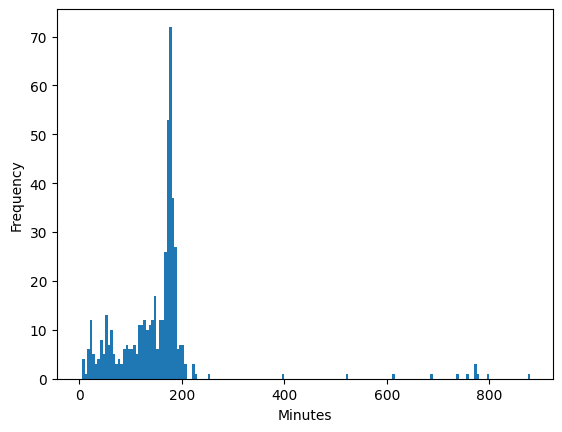

In [32]:
# Some statistics
print(f"Number of meetings:\n{len(ga_index_df)}\n")
print(f"Distribution over bodies:\n{ga_index_df['body'].value_counts()}\n")
print(f"Has transcripts:\n{ga_index_df['hasTranscript'].value_counts()}\n")
# Meeting durations
minutes = pd.to_timedelta(ga_index_df['duration']).dt.total_seconds() / 60
minutes = minutes[minutes > 0]

minutes.plot.hist(bins=range(0, int(minutes.max()) + 5, 5), xlabel="Minutes") # TODO: i get a type error here, how can i fix?

In [33]:
# inspect one transcript
meeting_slug = ga_index_df[ga_index_df["hasTranscript"]].iloc[0]["slug"] + ".json.gz"
SINGLE_MEETING = TRANSCRIPTS / meeting_slug 
print(SINGLE_MEETING)
assert SINGLE_MEETING.exists()

/home/janic/Workspace/Personal/repos/policy-pulse/data/transcripts/ga/c3/81/41.json.gz


In [34]:
import gzip
meeting = MeetingResponse.model_validate_json(gzip.decompress(SINGLE_MEETING.read_bytes()))
print(f"Keys of meeting:{meeting.model_fields_set}") 
# Here we are at the same point as described above, where we showed what the api can offer us!

Keys of meeting:{'transcript', 'url', 'video', 'disclaimer'}


In [35]:
assert meeting.transcript is not None
pprint(meeting.transcript.data[0].paragraphs[0], max_length=2, max_string=80)

Paragraph(
│   sentences=[
│   │   Sentence(text='Colleagues, we will start shortly.', start=942.37, end=944.69, topics=[]),
│   │   Sentence(text='If you take your seats, please.', start=944.69, end=946.05, topics=[]),
│   │   ... +14
│   ]
)

In [36]:
assert meeting.transcript is not None
# Look at a statement

rows = []
for s in meeting.transcript.data:
    text = " ".join(sen.text for p in s.paragraphs for sen in p.sentences)
    rows.append(
        {
            "meeting_id": meeting.video.slug,
            "seq": s.statement_number,
            "start": s.start,
            "affiliaton": s.speaker.affiliation if s.speaker else None,
            "function": s.speaker.function if s.speaker else None,
            "text": text,
            "n_words": len(text.split()),
        }
    )

meeting_df = pd.DataFrame(rows)
meeting_df.head()

,meeting_id,seq,start,affiliaton,function,text,n_words
0,ga/c3/81/41,1,942.37,3rd Committee,Chair,"Colleagues, we will start shortly. If you take...",272
1,ga/c3/81/41,2,1139.32,MNG,None,"Mr. Chair, Mongolia has the honour to introduc...",343
2,ga/c3/81/41,3,1305.52,3rd Committee,Chair,"Thank you, Mongolia. In addition to the delega...",34
3,ga/c3/81/41,4,1318.27,3rd Committee,Secretary,"Thank you, Mr. Chair. If any other countries w...",57
4,ga/c3/81/41,5,1383.82,3rd Committee,Chair,"Thank you, Secretary. A recorded vote has been...",62


<Axes: title={'center': 'Histogram, how often do statements have x words'}, xlabel='Words', ylabel='Frequency'>

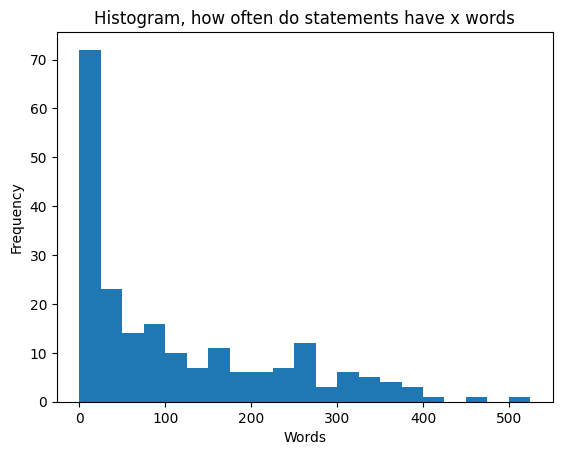

In [37]:
# Distribution of length of that specific meeting
max_words = int(meeting_df["n_words"].max())
meeting_df["n_words"].plot.hist(bins=range(0, max_words + 25, 25), xlabel="Words", title="Histogram, how often do statements have x words")

In [38]:
# Now make one large df out of all meeting records
paths = [TRANSCRIPTS / (slug + ".json.gz") for slug in ga_index_df[ga_index_df["hasTranscript"]]["slug"]]
assert all([f.exists() for f in paths])

rows = []
for f in paths:
    meeting = MeetingResponse.model_validate_json(gzip.decompress(f.read_bytes()))

    assert meeting.transcript is not None

    for s in meeting.transcript.data:
        text = " ".join(sen.text for p in s.paragraphs for sen in p.sentences)
        rows.append(
            {
                "meeting_id": meeting.video.slug,
                "body": meeting.video.body,
                "title": meeting.video.title,
                "session_number": meeting.video.session_number,
                "date": meeting.video.date,
                "pv_symbol": meeting.video.pv_symbol,
                "language": meeting.transcript.language,
                "seq": s.statement_number,
                "start": s.start,
                "affiliation": s.speaker.affiliation if s.speaker else None,
                "function": s.speaker.function if s.speaker else None,
                "text": text,
                "n_words": len(text.split()),
            }
        )

meetings_df = pd.DataFrame(rows)
meetings_df.head()

,meeting_id,body,title,session_number,date,pv_symbol,language,seq,start,affiliation,function,text,n_words
0,ga/c3/81/41,Third Committee,"Third Committee, 41st plenary meeting - Genera...",41st plenary meeting,2026-11-10T00:00:00.000Z,A/C.3/81/SR.41,en,1,942.37,3rd Committee,Chair,"Colleagues, we will start shortly. If you take...",272
1,ga/c3/81/41,Third Committee,"Third Committee, 41st plenary meeting - Genera...",41st plenary meeting,2026-11-10T00:00:00.000Z,A/C.3/81/SR.41,en,2,1139.32,MNG,None,"Mr. Chair, Mongolia has the honour to introduc...",343
2,ga/c3/81/41,Third Committee,"Third Committee, 41st plenary meeting - Genera...",41st plenary meeting,2026-11-10T00:00:00.000Z,A/C.3/81/SR.41,en,3,1305.52,3rd Committee,Chair,"Thank you, Mongolia. In addition to the delega...",34
3,ga/c3/81/41,Third Committee,"Third Committee, 41st plenary meeting - Genera...",41st plenary meeting,2026-11-10T00:00:00.000Z,A/C.3/81/SR.41,en,4,1318.27,3rd Committee,Secretary,"Thank you, Mr. Chair. If any other countries w...",57
4,ga/c3/81/41,Third Committee,"Third Committee, 41st plenary meeting - Genera...",41st plenary meeting,2026-11-10T00:00:00.000Z,A/C.3/81/SR.41,en,5,1383.82,3rd Committee,Chair,"Thank you, Secretary. A recorded vote has been...",62


<Axes: title={'center': 'Histogram, how often do statements have x words (over all meeting records of these two sessions)'}, xlabel='Words', ylabel='Frequency'>

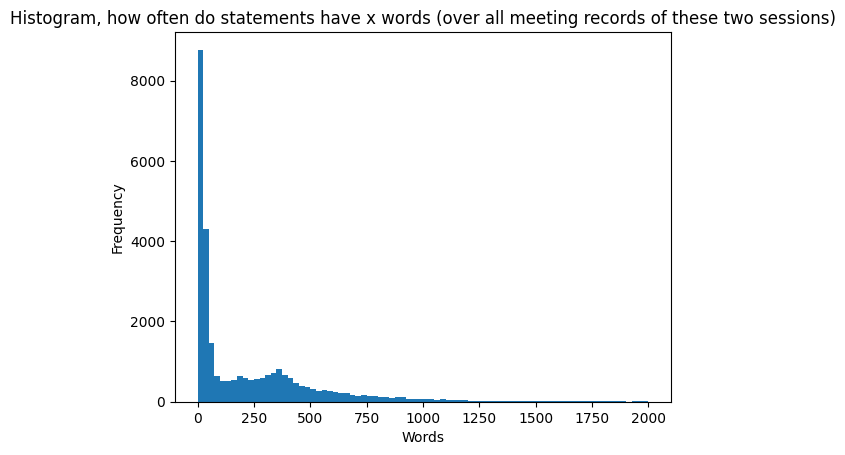

In [39]:
max_words = 2000#int(meetings_df["n_words"].max())
meetings_df["n_words"].plot.hist(bins=range(0, max_words + 25, 25), xlabel="Words", title="Histogram, how often do statements have x words (over all meeting records of these two sessions)")

### 1b. ODS official records

`meeting_records.jsonl` already holds the extracted page text per PV (`symbol`, `title`, `pages`). Session 80 plenary only covers PV.1–6, 17, 18, 36, 37, and there are almost no committee summary records (SR).

Questions to answer while looking at one PV:
- How does a speaker turn start? (e.g. `Mr. X (Country):` / `The President:`)
- What has to go: page headers/footers, the boilerplate on page 1, the "This record contains…" notice?
- Where do agenda items show up ("Agenda item 12")?

In [40]:
# load index.jsonl, filter to GA 80/81
ods_path = DATA / "session80" / "meeting_records.jsonl"
assert ods_path.exists()

rows = []
with open(ods_path) as f:
    for line in f:
        rows.append(json.loads(line))

print(f"Length of the index file:{len(rows)}")

Length of the index file:13


## 2. Coverage table

One row per meeting: `body`, `session`, `meeting_no`, `has_transcript`, `has_ods`, `source_used`.
Rule: ODS when it exists, transcript otherwise.

Note: the index only knows meetings the site lists. Missing meetings that were never listed won't show up; the highest meeting number per committee is a cheap sanity check.

## 3. Statement schema

One row = one speaker turn. Get the core columns working for both sources first, then add the extras as far as they come easily.

| column | type | notes |
|---|---|---|
| `statement_id` | str | e.g. `{meeting_id}#{seq}` |
| `source` | `ods` / `transcript` | |
| `session` | int | |
| `body` | `plenary` / `C1`…`C6` | |
| `meeting_id` | str | PV/SR symbol where known, else slug |
| `date` | date | |
| `seq` | int | order within the meeting |
| `affiliation` | str | ISO3; keep chair/President separate |
| `text` | str | |
| `n_words` | int | |
| *extra* `agenda_item` | str | |
| *extra* `speech_type` | str | general debate / explanation of vote before/after / right of reply |
| *extra* `on_behalf_of` | str | group statements; handle later |
| `url` | str | link back to the record (we show users a window plus this link) |

Suggestion: write one function per source, `parse_transcript(...) -> DataFrame` and `parse_pv(...) -> DataFrame`, that return exactly these columns, then `pd.concat`.
Check: on a meeting that both sources cover (an early session-80 PV), do the speaker sequences match?

In [41]:
# parse_transcript

In [42]:
# parse_pv

In [43]:
# statements = pd.concat([...]); filter to member states

## 4. Statistics

Questions worth answering before deciding anything about windows:

- Distribution of `n_words` (overall, per body, per source). How long is the long tail?
- Statements per country: who speaks most / least? Any member states with zero?
- Median length per country
- Statements per agenda item (if filled)
- How much text is formula? ("I thank…", "Mr. President…"): flag sentences/turns, don't delete them
- ODS vs transcript: do lengths differ systematically?

## 5. Sentences + windows

- One sentence splitter for both sources (e.g. `pysbd` or spaCy's `sentencizer`). Don't use the transcript API's own sentences: ~5% merge several sentences.
- Add a formula flag per sentence.
- Choose the window size from the statistics in section 4. The earlier design for comparison: statements ≥32 words, windows of whole sentences ≤100 words, ~25% overlap, last window anchored to the statement end.
- Output: a `windows` table (`window_id`, `statement_id`, `start_sentence`, `end_sentence`, `text`, `n_words`).